# Fitting Ares

This tutorial fits the simulated cluster Ares from its Lenstool parameter file, checks the fit, and compares the
recovered mass map with the simulation's true convergence.

Ares is one of the FF-SIMS clusters (Meneghetti et al. 2017): a semi-analytic cluster at $z = 0.5$ built with MOKA, lensed
and imaged like a Hubble Frontier Fields cluster. Its mass is two large clumps plus analytic subhalos, so it is a
bimodal, merging-like lens. It has many more multiple images than Hera (85 systems, 242 images, against 19 and 65),
which makes the fit slower but the mass map better constrained. Its multiple images and cluster members ship with
kappaccino under `catalogs/ares/`, and because it is a simulation, the true convergence and shear maps are known.

**Runtime.** On a laptop CPU (4 chains) the fit below takes about 40 minutes: 14 for the init stage, 22 for
NUTS and 5 for the figures. It uses the production likelihood with a shorter search and much shorter chains than a
production fit; the tutorial shows how to check convergence, and the last section lists what to change for a fit you can use.

**Before you start.** Run the notebook from the repository root, in an environment with kappaccino installed (see
the installation page). The truth comparison at the end needs the FF-SIMS truth maps in `data/imaging/ares/ffsims/`
(`python scripts/download_imaging.py`); without them the fit still runs and the comparison is skipped. The
[Hera tutorial](fit_hera.ipynb) explains each step in more detail.


## Set up the CPU chains

NUTS runs one chain per JAX CPU device. The devices have to be set before anything starts JAX, and reading a `.par`
file does (it converts arcseconds to kpc), so this comes first.

In [1]:
from kappaccino.cpu_runtime import configure_cpu_runtime

configure_cpu_runtime(4, "parallel")    # 4 chains

CPUPlan(chains=4, chain_method='parallel', threads_per_chain=None, jax_cpu_devices=4, available_cpu_ids=(0, 1, 2, 3, 4, 5, 6, 7), selected_cpu_ids=(0, 1, 2, 3, 4, 5, 6, 7), affinity_supported=False, blas_threads=1)

In [2]:
%matplotlib inline
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output

import numpyro.distributions as dist

from kappaccino.config import LikelihoodConfig, MemberPopulationConfig, SamplingConfig, ShearHaloConfig, TruthRecoveryConfig
from kappaccino.io.lenstool_par import config_from_lenstool_par
from kappaccino.pipeline import dry_run, run
from kappaccino.priors import describe, truncated_lognormal

if Path.cwd().name == "notebooks":       # run from the repository root, where the catalog paths are relative to
    os.chdir("..")
plt.style.use("src/kappaccino/plotting/style.mplstyle")

## The model from the Lenstool file

`catalogs/ares/source/ares_lenscluster.par` describes two cluster-scale dPIE halos (one on each clump), the member population on a
luminosity scaling relation, and the cosmology. `config_from_lenstool_par` turns it into a solver configuration;
the multiple images and the members come from the YAML catalogs next to it.

Priors are `numpyro.distributions` objects of the quantities the solver samples. The reader turns each Lenstool
`limit` into one: the ellipticity and angle limits become a uniform box in (e1, e2), and radii and dispersions are
sampled in log, so a uniform limit on the core radius becomes a log-uniform prior. `describe` prints each prior in the
coordinate it is sampled in ("in log" for the log of the value).

In [3]:
config = config_from_lenstool_par(
    "catalogs/ares/source/ares_lenscluster.par",
    image_catalog="catalogs/ares/images.yaml",
    member_catalog="catalogs/ares/members.yaml",
    output_dir="results/tutorial",
    run_name="ares",
)

# The member priors of Bergamini et al. 2019 replace the .par file's, as in run.xsh (see the next section).
z_lens = config.model.large_halos[0].z_lens
members = MemberPopulationConfig.bergamini2019(config.model.member_populations[0].id, "catalogs/ares/members.yaml", z_lens,
                                                prior_mag0=19.82)
config = replace(config, model=replace(config.model, member_populations=(members,)))

model = config.model
print(model.cosmology)
for halo in model.large_halos:
    print(f"halo {halo.id}: centre ({halo.x_centre:.2f}, {halo.y_centre:.2f}) arcsec, sigma {halo.v_disp:.0f} km/s, "
          f"core {halo.core_radius_kpc:.1f} kpc")
    for name, prior in halo.priors.items():
        print(f"    {name:16s} {describe(prior)}")
population = model.member_populations[0]
print(f"members: {population.catalog_path}, mag0 = {population.mag0}, sigma* = {population.sigma} km/s, rcut* = {population.cutkpc} kpc")
for name in ("sigma_prior", "cutkpc_prior"):
    print(f"    {name:16s} {describe(getattr(population, name))}")

CosmologyConfig(H0=70.4, Om0=0.272, Ode0=0.728, w0=-1.0, class_name='FlatLambdaCDM')
halo O1: centre (20.00, -32.00) arcsec, sigma 950 km/s, core 122.6 kpc
    x_centre         Uniform(15, 25)
    y_centre         Uniform(-37, -27)
    e1               Uniform(-0.2679, 0.2679)
    e2               Uniform(-0.2679, 0.2679)
    core_radius_kpc  Uniform(3.423, 5.908) in log
    v_disp           TruncatedNormal(6.823, 0.2588, [6.215, 7.496]) in log
halo O2: centre (-40.00, 40.00) arcsec, sigma 950 km/s, core 122.6 kpc
    x_centre         Uniform(-45, -35)
    y_centre         Uniform(35, 45)
    e1               Uniform(-0.2679, 0.2679)
    e2               Uniform(-0.2679, 0.2679)
    core_radius_kpc  Uniform(3.423, 5.62) in log
    v_disp           TruncatedNormal(6.84, 0.1827, [6.397, 7.244]) in log
members: catalogs/ares/members.yaml, mag0 = auto, sigma* = 200.0 km/s, rcut* = 12.0 kpc
    sigma_prior      TruncatedNormal(5.241, 0.3399, [3.689, 6.215]) in log
    cutkpc_prior     Trunc

## What the `.par` file does not say

A few choices live outside the Lenstool model:

- **Member priors.** The priors of the member scaling relation are those of Bergamini et al. 2019
  (`MemberPopulationConfig.bergamini2019`, as in `run.xsh`), calibrated with MUSE kinematics: at L* = 19.82 mag, a
  cut radius of 12 &pm; 10 kpc on 2&ndash;60 kpc and a dispersion of 200 &pm; 70 km/s, with the pivot magnitude
  chosen from the images. They replace the generated `.par` priors (cut radius 270 &pm; 35 kpc on 160&ndash;800 kpc).
  With the `.par` prior, the members were nearly untruncated, every one of the 334 members had to be modeled
  exactly, and the fit was too slow for a tutorial.
- **Fewer members, fewer exact members.** For speed, members whose deflection at every image is below 0.1" are
  dropped (the GRF absorbs their small contribution), and the far-field guard and the classification headroom are
  tighter than the defaults (`far_field_cut_radii=1.5`, `cut_radius_inflation=2`), so fewer members need the exact
  kernel.
- **External shear.** As for Hera, the model adds a free external shear.
- **No softening.** Ares' subhalos are analytic profiles, not N-body particles, so there is no resolution scale to
  match: the member cores stay as the scaling relation gives them (Hera adds the simulation's softening length).
- **Likelihood.** The production likelihood: the image-plane GP plus a Gaussian random field of unmodeled mass with a
  knee spectrum, shared by all images (see the likelihoods page).
- **Search and sampling.** 64 search starts, 200 warmup and 100 samples per chain, against 256 starts and 250 + 100
  for production.
- **Truth.** The FF-SIMS convergence and shear maps, so that the run also reports the mass recovery.


In [4]:
z_lens = model.large_halos[0].z_lens

grf_likelihood = LikelihoodConfig(
    likelihood_mode="gp_image_plane",
    gp_kernel="knee",
    gp_blocks="all",
    gp_knee_project_modes=("translation", "convergence", "shear"),
    sigma_sel_prior=None,
    gp_knee_gamma=4.0,
    gp_knee_gamma_prior=None,
    gp_knee_scales_arcsec=(0.2, 100.0),
    gp_knee_prior=truncated_lognormal(6.0, 0.6, low=2.5, high=8.0),
    gp_knee_start_arcsec=6.0,
    gp_sigma_alpha_prior=truncated_lognormal(0.08, 0.5, low=1e-4, high=0.5),
    gp_sigma_alpha_start_arcsec=0.08,
    gp_knee_ell_prior=truncated_lognormal(1.0, 0.4, low=0.4, high=3.0),
    gp_knee_ell_start_arcsec=1.0,
)

truth_dir = Path("data/imaging/ares/ffsims")
have_truth = (truth_dir / "kappa_z9_0.fits").is_file()
truth = TruthRecoveryConfig(**({f"{name}_true_fits": str(truth_dir / f"{name}_z9_0.fits") for name in ("kappa", "gammax", "gammay")}
                               if have_truth else {}))

config = replace(
    config,
    model=replace(model, large_halos=model.large_halos + (ShearHaloConfig.free("S1", z_lens),)),
    likelihood=grf_likelihood,
    search=replace(config.search, n_starts=64),
    sampling=SamplingConfig(warmup=200, samples=100, max_tree_depth=8, target_accept=0.8),
    members=replace(config.members, centering="auto", far_field_cut_radii=1.5, cut_radius_inflation=2.0,
                    min_deflection_arcsec=0.1),
    runtime=replace(config.runtime, quiet=True),
    truth=truth,
).validate()
print("truth maps found" if have_truth else "no truth maps: the comparison at the end is skipped")

truth maps found


## Check the configuration

`dry_run` builds the model and classifies the members without fitting or writing anything: the number of parameters,
which members are modeled exactly and which in the far-field approximation, and the search and sampling sizes.

In [5]:
with capture_output():                   # the classification tables also go to the console; the summary is enough here
    summary = dry_run(config)
{key: summary[key] for key in ("likelihood", "parameters", "images", "families", "members", "provisional_classification", "sampling")}

{'likelihood': 'grf_gp (GRF of unmodelled mass with a knee spectrum + image-plane GP, all blocks)',
 'parameters': 325,
 'images': 242,
 'families': 85,
 'members': 65,
 'provisional_classification': {'exact': 65,
  'mandatory': 65,
  'far_field': 0,
  'inflated_cut_kpc': 9.860916070386475},
 'sampling': {'chains': 4, 'warmup': 200, 'samples': 100, 'max_tree_depth': 8}}

## Run the fit

`run` does both stages: **init** (a multi-start MAP search for the posterior mode, then the chain starts) and **final**
(NUTS from that mode, then the tables, figures and maps). With `quiet=True` the progress goes only to the log files
under `results/tutorial/ares/`; `capture_output` also hides the progress bars and tables that are printed regardless.
Running the cell again reloads the finished stages instead of refitting.

In [6]:
with capture_output():
    result = run(config)
print({k: f"{v / 60:.1f} min" for k, v in result.timing.items()})

{'sampling': '22.4 min', 'outputs': '5.2 min', 'init': '13.8 min', 'total': '41.5 min'}


### Did it work?

Three things to check first. The last line of the init log says whether the search is **robust** (several independent
starts reach the best basin) or **fragile** (only one does):

In [7]:
root = result.paths.root
print((root / "init/logs/init.log").read_text().splitlines()[-1][20:])

[   830.4s] [init] members at the start: scatter 0.200, unit deviation rms 1.09 (prior 1), max |deviation| 7.44 (16), sigma 76-872 km/s, r_cut 0.6-1855.9 kpc


`run_summary.txt` gives the images recovered, the image-plane residual and the sampler diagnostics (split R-hat, ESS,
divergences):

In [8]:
print((root / "final/tables/run_summary.txt").read_text())

Run summary                                                               
  Run                                                                     
    name                                  ares                            
    output                                results/tutorial/ares/final     
    stages                                init run, final run             
                                                                          
  Data and model                                                          
    images, families                      242, 85                         
    members: exact, far-field             65, 0                           
    sampled parameters                    325                             
    global parameters, dof                25, 289                         
                                                                          
  Images at the best fit                                                  
    recovered / observed 

### Are the chains converged?

No. The sampler section above reports a maximum split R-hat far above 1.01 and an effective sample size of a few draws
for some global parameters, while the source positions mix well (R-hat at most 1.03). With 200 warmup steps, the four
chains have not yet found the same region. `chain_convergence.csv` lists every parameter:


In [9]:
convergence = pd.read_csv(root / "final/tables/chain_convergence.csv")
print(f"{(convergence.split_rhat > 1.01).sum()} of {len(convergence)} parameters have R-hat > 1.01")
convergence.sort_values("split_rhat", ascending=False).head(10).round(2)

250 of 325 parameters have R-hat > 1.01


,parameter,split_rhat,ess
9,O2.e2,1.81,3.17
110,potfile.31.radius_offset,1.63,3.36
10,O2.core_radius_kpc,1.54,3.76
98,potfile.15.radius_offset,1.48,9.84
19,potfile.radius_log_scatter,1.46,3.86
8,O2.e1,1.39,4.10
5,O1.v_disp,1.33,5.07
14,potfile.sigma,1.27,7.08
15,potfile.cutkpc,1.26,8.31
93,potfile.9.radius_offset,1.26,6.11


The final log names the directions along which the chains disagree, in units of the within-chain spread:

In [10]:
for line in (root / "final/logs/final.log").read_text().splitlines():
    if "slow mode" in line:
        print(line[31:])

 [nuts] slow mode 1: chain means 6.8 within-chain sd apart (scores [-0.857, 0.295, 0.382, 0.18]); member radius_offsets 0.57, O2.e2 0.35, member velocity_offsets 0.31, O2.core_radius_kpc 0.27, potfile.radius_log_scatter 0.27, O2.e1 0.26, O1.v_disp 0.23, O1.e2 0.16
 [nuts] slow mode 2: chain means 3.2 within-chain sd apart (scores [-0.116, 0.265, -0.747, 0.598]); member radius_offsets 0.58, potfile.cutkpc 0.42, member velocity_offsets 0.37, source beta_y 0.28, potfile.beta_radius 0.28, source beta_x 0.28, potfile.radius_log_scatter 0.15, potfile.sigma 0.15


Here the chains sit apart along the member offsets (the deviations of individual members from the scaling relation),
mostly in the cut radius, together with the cut radius of the relation itself (`cutkpc`) and the shape of the halo
O2. The final log also reports that about a fifth of the `cutkpc` draws sit at the lower bound of its prior, while a
few bright members take large cut radii through their offsets: the relation and the individual members trade the
same mass, and short chains do not cross that degeneracy. The cure is longer chains (see the last section).

Until then, read the rest as a **best-fit model with indicative uncertainties**: the best fit and the image recovery
are meaningful, but the posterior intervals are too narrow and too dependent on where each chain started.


## The posterior

`result.posterior.physical` holds the draws in physical units, one column per parameter; the
[posterior output reference](../posterior.md) defines each one with its units. `posterior_summary.csv` summarizes every
parameter; the global ones (the two halos, the shear, the member scaling relation and its scatter, and
the error model) are below. The per-member offsets and the source positions follow in the same table.

In [11]:
posterior = pd.read_csv(root / "final/tables/posterior_summary.csv")
globals_ = posterior[posterior.family.isin(["large", "scaling", "member_velocity_scatter", "error_scale"])]
globals_[["parameter", "median", "p16", "p84", "best_fit", "r_hat", "n_eff"]].round(3)

,parameter,median,p16,p84,best_fit,r_hat,n_eff
0,O1.x_centre,19.678,19.482,19.848,19.783,1.082,25.460
1,O1.y_centre,-32.125,-32.331,-31.933,-32.125,1.015,155.896
2,O1.e1,0.008,-0.001,0.018,0.001,1.133,13.541
3,O1.e2,-0.175,-0.184,-0.165,-0.185,1.190,7.566
4,O1.core_radius_kpc,72.966,66.750,79.214,72.444,1.149,11.207
5,O1.v_disp,1204.960,1179.769,1221.743,1203.673,1.334,5.032
6,O2.x_centre,-40.354,-40.656,-40.137,-40.335,1.037,113.068
7,O2.y_centre,40.585,40.194,41.020,40.451,1.040,77.056
8,O2.e1,-0.154,-0.183,-0.133,-0.140,1.390,4.105
9,O2.e2,-0.180,-0.227,-0.161,-0.171,1.815,3.170


## Image-plane residuals

For each observed image, `image_fit_quality.csv` compares its position with the one the model predicts from its
source: the exact image solver at the best fit.

242 images: rms 0.48, median 0.36, max 1.46 arcsec


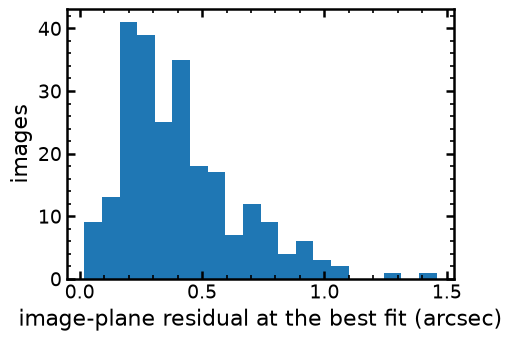

,family_id,image_label,z_source,image_residual_arcsec,magnification_model,image_recovery_status
239,121,121.b,5.45,1.458,-2.089,recovered
172,73,73.c,3.60,1.279,10.002,recovered
96,40,40.a,2.78,1.098,4.155,recovered
169,74,74.b,3.55,1.081,4.434,recovered
147,61,61.c,3.36,1.001,7.054,recovered
230,114,114.b,4.94,0.963,6.693,recovered
14,7,7.b,1.17,0.958,8.105,recovered
93,38,38.b,2.75,0.941,-5.022,recovered


In [12]:
images = pd.read_csv(root / "final/tables/image_fit_quality.csv")
residual = images.image_residual_arcsec
print(f"{len(images)} images: rms {np.sqrt(np.mean(residual ** 2)):.2f}, median {residual.median():.2f}, "
      f"max {residual.max():.2f} arcsec")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(images.image_residual_arcsec, bins=20)
ax.set_xlabel("image-plane residual at the best fit (arcsec)")
ax.set_ylabel("images")
display(fig)
plt.close(fig)
images.sort_values("image_residual_arcsec", ascending=False)[
    ["family_id", "image_label", "z_source", "image_residual_arcsec", "magnification_model", "image_recovery_status"]].head(8).round(3)

## Mass map against the truth

The convergence of the best posterior draw at $z_s = 9$ (the redshift of the FF-SIMS maps), on the grid of the true
map. The white line in the first two panels is the model's critical curve at $z_s = 9$, and the cyan points are the
observed images. Residuals near the cluster centre show what the parametric model (two halos plus members on a scaling
relation) cannot capture.

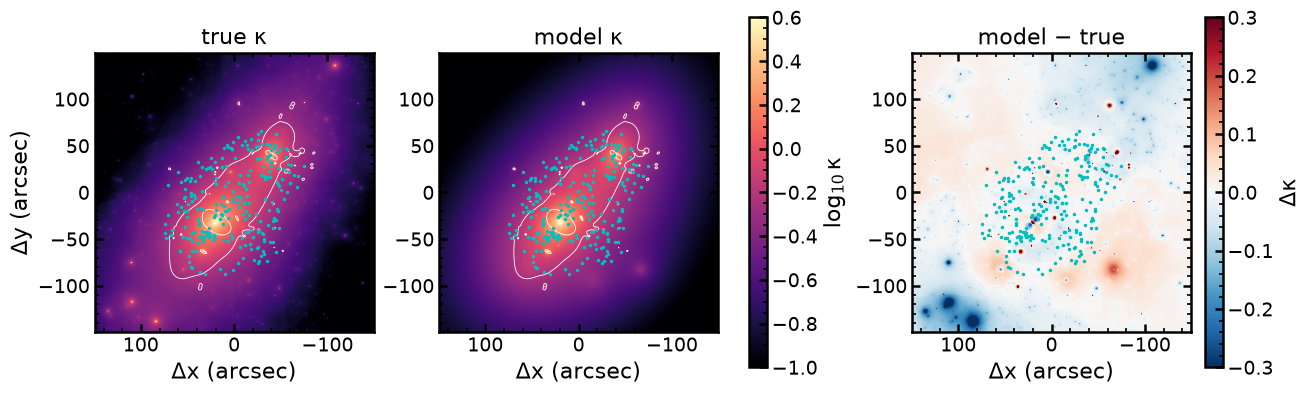

In [13]:
from kappaccino.diagnostics.truth_recovery import diagnostic_grid, grid_arcsec, lens_quantities, load_truth_fits, sample_on_grid

if have_truth:
    kappa_true_native, wcs_native = load_truth_fits(truth_dir / "kappa_z9_0.fits")
    wcs, shape = diagnostic_grid(wcs_native, kappa_true_native.shape, 256)
    kappa_true = sample_on_grid(kappa_true_native, wcs_native, wcs, shape)
    x, y = grid_arcsec(result.state, wcs, shape)

    best = int(np.argmax(result.posterior.log_prob))
    theta = result.posterior.samples[best]
    fields = lens_quantities(result.evaluator, theta, 9.0, x.ravel(), y.ravel())
    kappa_model = fields["kappa"].reshape(shape)
    det_a = fields["detA"].reshape(shape)

    extent = [x[0, 0], x[0, -1], y[0, 0], y[-1, 0]]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
    for ax, image, title in ((axes[0], kappa_true, "true $\\kappa$"), (axes[1], kappa_model, "model $\\kappa$")):
        shown = ax.imshow(np.log10(np.clip(image, 1e-2, None)), origin="lower", extent=extent, vmin=-1.0, vmax=0.6, cmap="magma")
        ax.contour(x, y, det_a, levels=[0.0], colors="white", linewidths=0.6)
        ax.set_title(title)
    fig.colorbar(shown, ax=axes[:2], label="log$_{10}\\,\\kappa$", shrink=0.85)
    residual = axes[2].imshow(kappa_model - kappa_true, origin="lower", extent=extent, vmin=-0.3, vmax=0.3, cmap="RdBu_r")
    axes[2].set_title("model $-$ true")
    fig.colorbar(residual, ax=axes[2], label="$\\Delta\\kappa$", shrink=0.85)
    obs = result.state.images
    for ax in axes:
        ax.plot(np.asarray(obs.x_obs), np.asarray(obs.y_obs), "c.", ms=3)
        ax.set_xlabel("$\\Delta x$ (arcsec)")
    axes[0].set_ylabel("$\\Delta y$ (arcsec)")
    display(fig)
    plt.close(fig)

The run also compares the projected mass within apertures around the truth's peak, over the posterior draws
(`truth_recovery_m2d_aperture_profile.csv`):

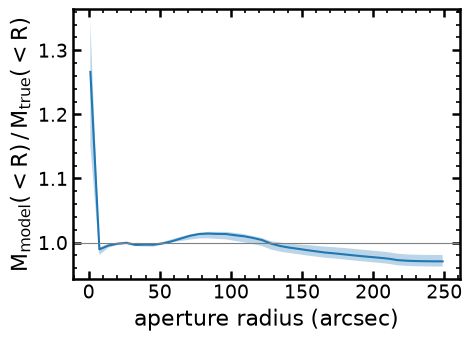

R =  32.9": model / truth = 0.996 (0.995 to 0.998)
R =  58.3": model / truth = 1.002 (1.000 to 1.005)
R = 102.8": model / truth = 1.011 (1.003 to 1.015)


In [14]:
if have_truth:
    aperture = pd.read_csv(root / "final/tables/truth_recovery_m2d_aperture_profile.csv")
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.fill_between(aperture.radius_arcsec, aperture.m2d_ratio_q16, aperture.m2d_ratio_q84, alpha=0.3, lw=0)
    ax.plot(aperture.radius_arcsec, aperture.m2d_ratio_median)
    ax.axhline(1.0, color="0.5", lw=0.8)
    ax.set_xlabel("aperture radius (arcsec)")
    ax.set_ylabel("$M_\\mathrm{model}(<R)\\,/\\,M_\\mathrm{true}(<R)$")
    display(fig)
    plt.close(fig)
    for r in (30, 60, 100):
        row = aperture.iloc[(aperture.radius_arcsec - r).abs().argmin()]
        print(f"R = {row.radius_arcsec:5.1f}\": model / truth = {row.m2d_ratio_median:.3f} ({row.m2d_ratio_q16:.3f} to {row.m2d_ratio_q84:.3f})")

The band is the 16 to 84% range over the draws, so with these chains it understates the uncertainty (see the convergence
check above). Images constrain the mass inside roughly the radius of the outermost images; beyond it the model
extrapolates.

## The other outputs

Every run writes to `<output_dir>/<run_name>/`. The figures are PDFs under `final/figures/`:

In [15]:
sorted(p.name for p in (root / "final/figures").glob("*.pdf"))

['ares_lenscluster_chain_traces.pdf',
 'ares_lenscluster_corner_combined.pdf',
 'ares_lenscluster_corner_globals.pdf',
 'ares_lenscluster_covariance_corner.pdf',
 'ares_lenscluster_covariance_errors_both_planes.pdf',
 'ares_lenscluster_critical_curves.pdf',
 'ares_lenscluster_far_field_accuracy.pdf',
 'ares_lenscluster_gp_correction_correlation.pdf',
 'ares_lenscluster_gp_kernel_curves.pdf',
 'ares_lenscluster_gp_scale_posteriors.pdf',
 'ares_lenscluster_image_recovery.pdf',
 'ares_lenscluster_image_residual_histogram.pdf',
 'ares_lenscluster_magnification_recovery.pdf',
 'ares_lenscluster_member_constraints.pdf',
 'ares_lenscluster_member_deviations.pdf',
 'ares_lenscluster_potfile_corner.pdf',
 'ares_lenscluster_scaling_relation.pdf',
 'ares_lenscluster_total_grf_dimensionless_power.pdf',
 'ares_lenscluster_truth_recovery_m2d_aperture_ratio.pdf',
 'ares_lenscluster_truth_recovery_residuals.pdf',
 'ares_lenscluster_whitened_image_residuals.pdf']

## From here to a production fit

- More search starts: `search=replace(config.search, n_starts=256)`.
- Longer chains: raise `warmup` and `samples` until the maximum R-hat is below 1.01 and the minimum ESS is in the
  hundreds. The slow directions reported in `final.log` show what is holding the chains back.
- Check the chain traces (`*_chain_traces.pdf`) and `run_summary.txt` before trusting the posterior intervals.
- A changed configuration needs a new `run_name`: `run` refuses to resume a run with a different configuration.